# 10. Quick comparison of algorithms with default settings

A first look at how different algorithms do **out of the box**: library defaults, **one** train/test split, **no cross-validation, no tuning**.

**How to read the result**
- One split gives no error bars. Elsewhere in this project the fold-to-fold spread is about 0.003 to 0.004 AUC, so gaps smaller than that are not meaningful.
- Defaults favour some models over others (a default random forest overfits, a default logistic regression is heavily regularised). This is a first look, not a verdict.
- **Train AUC vs test AUC** is the overfitting signal: a big gap means the model memorised the training data.
- The only things beyond library defaults are preprocessing that a model needs to run at all (imputing, scaling, encoding), a fixed `random_state`, and `n_jobs=4` on the forest to protect memory.

In [1]:
# Build the feature table in two views and create one stratified 80/20 split
import sys, time, gc
# make the project's src/ package importable from the notebooks folder
sys.path.append("..")

import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.features import clean, add_features, one_hot

# raw application table
df = pd.read_csv("../data/raw/HC_application_train.csv")
y = df["TARGET"].reset_index(drop=True)
# same feature table as in earlier notebooks
X = add_features(clean(df.drop(columns="TARGET")))
# attach the pre-computed aggregate tables
for name in ["bureau", "previous", "installments"]:
    X = X.join(pd.read_pickle(f"../data/processed/{name}.pkl"), on="SK_ID_CURR")
X = X.drop(columns="SK_ID_CURR").reset_index(drop=True)
# free memory, the data is large
del df; gc.collect()

# one fixed split shared by all models, so the comparison is fair
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=42)

# view 1: native categories (LightGBM, XGBoost)
# keep a separate copy so the one-hot view is built from the raw columns
X_cat = X.copy()
# text columns become native categories
for c in X_cat.select_dtypes(include=["object", "string"]):
    X_cat[c] = X_cat[c].astype("category")

# view 2: one-hot, float32 (logistic regression, random forest)
# numeric-only matrix (float32) for models that cannot read categories
X_oh = one_hot(X)
# the raw table is no longer needed
del X; gc.collect()
print("native:", X_cat.shape, " one-hot:", X_oh.shape, " train/test:", len(idx_tr), len(idx_te))

native: (307511, 518)  one-hot: (307511, 656)  train/test: 246008 61503


**Insight:** the native view has 518 features and the one-hot view 656. The split is 246,008 training and 61,503 test applicants (80/20).

## Train the first four models
The helper `run()` fits one model on the training rows and records its AUC on both the training and the test rows. The gap between the two shows how much the model overfits. The slow random forest is run in a separate cell afterwards.

In [2]:
# Helper that fits a model and records train and test AUC, then run four default models
# collects one result row per model
rows = []

# fit, time it, and score on train and test
def run(label, model, Xm, note=""):
    t0 = time.time()
    model.fit(Xm.iloc[idx_tr], y.iloc[idx_tr])
    secs = time.time() - t0
    # AUC computed from predicted probabilities of class 1
    score = lambda idx: roc_auc_score(y.iloc[idx], model.predict_proba(Xm.iloc[idx])[:, 1])
    rows.append({"model": label, "train AUC": score(idx_tr), "test AUC": score(idx_te), "fit seconds": round(secs), "note": note})
    print(rows[-1], flush=True)
    # free memory before the next model
    del model; gc.collect()

# baseline: always predicts the base rate, so AUC must be 0.5
run("Dummy (always the base rate)", DummyClassifier(strategy="prior"), X_oh)
# needs imputing and scaling to run at all
run("Logistic regression", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()), X_oh,
    "median-impute + scale (needed to run)")
# library defaults on native categories
run("LightGBM", lgb.LGBMClassifier(random_state=42, verbose=-1), X_cat)
# library defaults, with native categories enabled
run("XGBoost", xgb.XGBClassifier(random_state=42, tree_method="hist", enable_categorical=True), X_cat)

{'model': 'Dummy (always the base rate)', 'train AUC': 0.5, 'test AUC': 0.5, 'fit seconds': 1, 'note': ''}


/Users/dhanyarajendran/Desktop/NeueFische/myproject/Home-Credit-Default-Risk/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'model': 'Logistic regression', 'train AUC': 0.7782868691395688, 'test AUC': 0.7740178739592016, 'fit seconds': 51, 'note': 'median-impute + scale (needed to run)'}


{'model': 'LightGBM', 'train AUC': 0.8391197520019196, 'test AUC': 0.7844520045283557, 'fit seconds': 12, 'note': ''}


{'model': 'XGBoost', 'train AUC': 0.9123527142239338, 'test AUC': 0.7725341086355773, 'fit seconds': 18, 'note': ''}


**Insight:** the dummy scores 0.5 as expected. Logistic regression printed a convergence warning because it hit the default limit of 100 iterations. The comparison is collected in the Result table below.

The random forest goes last: fully grown trees on this many rows and columns are the heaviest step.

In [3]:
# Fit the default random forest, the slowest model, and record its scores
run("Random forest", RandomForestClassifier(random_state=42, n_jobs=4), X_oh, "100 trees, n_jobs=4")

{'model': 'Random forest', 'train AUC': 1.0, 'test AUC': 0.732097515036541, 'fit seconds': 105, 'note': '100 trees, n_jobs=4'}


**Insight:** the forest took 105 seconds, the longest of all models, and fits the training data perfectly (train AUC 1.0) while reaching only 0.7321 on the test rows.

## Result

The table sorts the models by test AUC and adds the train-test gap.

In [4]:
# Collect the results, sort by test AUC and add the train-test gap
# best test AUC first
res = pd.DataFrame(rows).sort_values("test AUC", ascending=False).reset_index(drop=True)
# large gap = the model memorised the training data
res["train-test gap"] = res["train AUC"] - res["test AUC"]
res[["model", "train AUC", "test AUC", "train-test gap", "fit seconds", "note"]].round(4)

,model,train AUC,test AUC,train-test gap,fit seconds,note
0,LightGBM,0.8391,0.7845,0.0547,12,
1,Logistic regression,0.7783,0.7740,0.0043,51,median-impute + scale (needed to run)
2,XGBoost,0.9124,0.7725,0.1398,18,
3,Random forest,1.0000,0.7321,0.2679,105,"100 trees, n_jobs=4"
4,Dummy (always the base rate),0.5000,0.5000,0.0000,1,


**Insight:** only LightGBM's lead over logistic regression (0.7845 against 0.7740, a difference of 0.0105) is clearly above the 0.003 to 0.004 noise, and this is still a single split. The overfitting gap grows from 0.0043 (logistic regression) through 0.0547 (LightGBM) and 0.1398 (XGBoost) to 0.2679 (random forest).

A bar chart of the test AUC makes the ranking easy to scan; the dashed line marks 0.5, the level of random guessing.

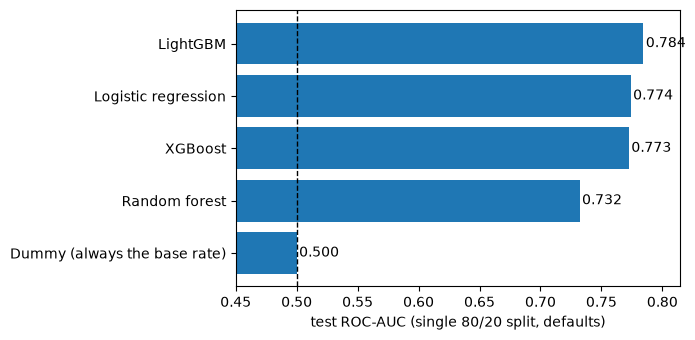

In [5]:
# Bar chart of test AUC per model, saved to assets
fig, ax = plt.subplots(figsize=(7, 3.5))
# reversed so the best model is at the top
ax.barh(res["model"][::-1], res["test AUC"][::-1])
# 0.5 = no better than chance
ax.axvline(0.5, color="k", ls="--", lw=1)
# start the axis near 0.5 so differences are visible, but note this exaggerates them
ax.set_xlim(0.45, max(res["test AUC"]) + 0.03); ax.set_xlabel("test ROC-AUC (single 80/20 split, defaults)")
# print the exact value next to each bar
for i, v in enumerate(res["test AUC"][::-1]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.savefig("../assets/default_model_comparison.png", dpi=150); plt.show()

**Insight:** the chart shows the same ordering as the table. The random forest sits well below the other three models, while the gaps between LightGBM, logistic regression and XGBoost look larger than they are because the axis starts at 0.45.

## Reading it
- **Ranking (test AUC):** LightGBM 0.7845, logistic regression 0.7740, XGBoost 0.7725, random forest 0.7321, dummy 0.5. One split, no error bars; the gap between logistic regression and XGBoost (0.0015) is smaller than the usual 0.003 to 0.004 spread, so treat those two as tied.
- **Overfitting:** the default random forest memorises the training data (train AUC 1.000, test 0.732, gap 0.27). Default XGBoost also overfits heavily (0.912 vs 0.773, gap 0.14). LightGBM's defaults are more conservative (gap 0.055). Logistic regression barely overfits (gap 0.004) but is limited by being linear.
- **Logistic regression hit the iteration limit** (default `max_iter=100`, convergence warning), so its default score is slightly pessimistic; it still beats two of the tree models.
- **Compared with tuned, cross-validated LightGBM (about 0.79):** untuned LightGBM is about 0.007 lower, and untuned XGBoost and forest are well below. Tuning and early stopping matter mostly for the overfitting models, which is the reason to tune XGBoost and the forest before drawing a final conclusion.
